# Assignment #4 | Anggota 4 (Miko): Interpretasi Model (Instruksi 6 & 7)

Notebook ini menjawab pertanyaan kedua di soal: *apakah interpretasi model bisa membantu kita memahami model dan menemukan masalah di data?*

Alatnya SHAP (utama) dan LIME (pembanding). Yang dijelaskan adalah model ensemble RF dan CNN dengan preprocessing E5, yaitu baseline yang dikunci Anggota 1. 

Kalau dataset final dari Erdi dan Marco sudah ada, cukup isi sel **A10 (`FINAL`)** lalu `Run All`.

| Bagian | Isi | Instruksi |
|---|---|---|
| A | Kerangka bersama (disalin dari notebook Thufail) dan konfigurasi dataset final | — |
| B | Menghitung SHAP secara *out-of-fold* | 6 |
| C | Interpretasi global: Fitur apa yang paling dipakai model? | 6 |
| D | Interpretasi lokal: Mengapa pasien tertentu diprediksi begitu (SHAP vs LIME)? | 6 |
| E | Dari penjelasan model ke kualitas data, terdiri dari fitur langka, fitur redundan, cek leakage, analisis salah prediksi | 7 |
| F | Ringkasan temuan dan bahan diskusi | 9 (bagian Miko) |

# BAGIAN A | Kerangka bersama

Sel A1–A8 adalah **salinan persis** dari `Assignment4_Anggota1.ipynb` (setup, load data, split terkunci, fold CV terkunci, preprocessing E0/E5, metrik, model ensemble, `evaluate_cv`). 

Tujuannya agar model, split, dan fold di notebook ini identik dengan yang dipakai anggota lain. Penjelasan tiap sel ada di notebook Anggota 1, jadi tidak diulang di sini.

Split dan fold dibaca dari `./artifacts/split.json` dan `./artifacts/cv_splits.json`, tidak dibuat ulang.

Kalau Anggota 1 mengubah kerangkanya, salin ulang sel-sel ini.

## A1. Setup

In [ ]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix)

# Konfigurasi
PATH       = "./dataset/heart_disease_cleveland.csv"
ART_DIR    = "./artifacts"
SEED       = 42
TARGET     = "num"
N_SPLITS   = 5
N_REPEATS  = 3
TEST_SIZE  = 0.2
RF_PARAMS  = {"n_estimators": 194, "max_depth": 43}                      # dari Assignment #3
CNN_PARAMS = {"filters": 34, "kernel_size": 2, "dense_units": 50,
              "learning_rate": 0.001, "epochs": 50, "batch_size": 32}     # dari Assignment #3
os.makedirs(ART_DIR, exist_ok=True)

print("sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
try:
    import tensorflow as tf; print("tensorflow", tf.__version__)
    import logging; logging.getLogger("tensorflow").setLevel(logging.ERROR)   # sembunyikan peringatan retracing yang tidak berbahaya
except Exception as e:
    print("TensorFlow belum terpasang:", e)

sklearn 1.9.1 | numpy 2.5.3 | pandas 3.0.6


tensorflow 2.21.0


## A2. Load data

In [2]:
df = pd.read_csv(PATH).rename(columns={"target": TARGET})
df.insert(0, "row_id", np.arange(len(df)))

print("Bentuk:", df.shape)
print("Missing per kolom (data penuh):", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Duplikat persis:", df.drop(columns="row_id").duplicated().sum())
print("Distribusi target (data penuh):", df[TARGET].value_counts().sort_index().to_dict())
assert set(df[TARGET].unique()) == {0, 1}, "target harus biner 0/1"
df.head(3)

Bentuk: (303, 15)
Missing per kolom (data penuh): {'ca': 4, 'thal': 2}
Duplikat persis: 0
Distribusi target (data penuh): {0: 164, 1: 139}


,row_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


## A3. Split train/test (dibaca dari `split.json`)

In [ ]:
def get_split(df):
    p = f"{ART_DIR}/split.json"
    if os.path.exists(p):
        ids = json.load(open(p))
    else:
        tr, te = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df[TARGET])
        ids = {"train": sorted(tr.row_id.tolist()), "test": sorted(te.row_id.tolist())}
        json.dump(ids, open(p, "w"))
    train_df = df[df.row_id.isin(ids["train"])].reset_index(drop=True)
    test_df  = df[df.row_id.isin(ids["test"])].reset_index(drop=True)
    assert not set(train_df.row_id) & set(test_df.row_id), "train/test overlap!"
    return train_df, test_df

train_df, test_df = get_split(df)
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Kelas train:", train_df[TARGET].value_counts().sort_index().to_dict())
# Dari sini ke bawah, test_df hanya  dipakai oleh final_test_eval() di Bagian D.

Train: (242, 15) | Test: (61, 15)
Kelas train: {0: 131, 1: 111}


## A4. Fold CV (dibaca dari `cv_splits.json`)

In [4]:
def get_cv_splits(train_df):
    p = f"{ART_DIR}/cv_splits.json"
    if os.path.exists(p):
        return [(np.array(a), np.array(b), r) for a, b, r in json.load(open(p))]
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    out = []
    for i, (a, b) in enumerate(rskf.split(train_df, train_df[TARGET])):
        out.append((train_df.row_id.values[a].tolist(), train_df.row_id.values[b].tolist(), i // N_SPLITS))
    json.dump(out, open(p, "w"))
    return [(np.array(a), np.array(b), r) for a, b, r in out]

cv = get_cv_splits(train_df)
print("Jumlah fold:", len(cv), "| ukuran validasi fold-0:", len(cv[0][1]))

Jumlah fold: 15 | ukuran validasi fold-0: 49


## A5. Preprocessing E0 dan E5

In [ ]:
# Konstanta kolom (dari notebook Assignment #3)
continuous_cols   = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols  = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
NOMINAL_COLS      = ['cp', 'restecg', 'thal']
ORDINAL_COLS      = ['ca', 'slope']
BINARY_COLS       = ['sex', 'fbs', 'exang']
LOG_COLS          = ['chol', 'oldpeak']
MISSING_FLAG_COLS = ['ca', 'thal']
ENGINEERED_COLS   = ['hr_reserve', 'st_severity']


class IQRClipper(BaseEstimator, TransformerMixin):
    """Winsorize dengan batas IQR (baris tidak dihapus). Batas dihitung dari data fit (train saja)."""
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lo_, self.hi_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)


def _base_impute(tr, ev):
    """Imputasi median (kontinu) / modus (kategorikal). Fit hanya di train, transform ke train & eval."""
    num_imp = SimpleImputer(strategy='median').fit(tr[continuous_cols])
    cat_imp = SimpleImputer(strategy='most_frequent').fit(tr[categorical_cols])
    for d in (tr, ev):
        d[continuous_cols] = num_imp.transform(d[continuous_cols])
        d[categorical_cols] = cat_imp.transform(d[categorical_cols])


def preprocess_E0(tr_df, ev_df):
    """Baseline Assignment #2 dengan Imputasi + IQR outlier REMOVAL (drop baris train saja) + Min-Max di semua fitur mentah. Belum ada one-hot, flag missing, rekayasa fitur, atau log transform."""
    tr, ev = tr_df.copy(), ev_df.copy()
    y_tr = tr.pop(TARGET).to_numpy(dtype=int)

    _base_impute(tr, ev)
    for c in categorical_cols:
        tr[c] = tr[c].round().astype(int)
        ev[c] = ev[c].round().astype(int)

    q1, q3 = tr[continuous_cols].quantile(0.25), tr[continuous_cols].quantile(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    mask = ((tr[continuous_cols] >= lo) & (tr[continuous_cols] <= hi)).all(axis=1)
    y_tr = y_tr[mask.to_numpy()]
    tr = tr.loc[mask].reset_index(drop=True)

    feature_names = continuous_cols + categorical_cols
    scaler = MinMaxScaler().fit(tr[feature_names])
    X_train = scaler.transform(tr[feature_names])
    X_eval = scaler.transform(ev[feature_names])
    return X_train, y_tr, X_eval, feature_names


def preprocess_E5(tr_df, ev_df):
    """E4 + flag missing (_missing) untuk ca & thal (checklist poin 1).
    Setara dengan preprocess_current_notebook, tanpa restriksi ke selected_feature_names (seleksi fitur GA+CSO dipisah."""
    tr, ev = tr_df.copy(), ev_df.copy()
    y_tr = tr.pop(TARGET).to_numpy(dtype=int)

    missing_flag_cols = [f'{c}_missing' for c in MISSING_FLAG_COLS]
    for d in (tr, ev):
        for c in MISSING_FLAG_COLS:
            d[f'{c}_missing'] = d[c].isna().astype(int)

    _base_impute(tr, ev)
    for c in NOMINAL_COLS + BINARY_COLS + ORDINAL_COLS:
        tr[c] = tr[c].round().astype(int)
        ev[c] = ev[c].round().astype(int)

    for d in (tr, ev):
        d['hr_reserve'] = d['thalach'] - (220 - d['age'])
        d['st_severity'] = d['oldpeak'] * d['slope']

    for c in LOG_COLS:
        tr[c] = np.log1p(tr[c])
        ev[c] = np.log1p(ev[c])

    clip_cols = continuous_cols + ENGINEERED_COLS
    clipper = IQRClipper().fit(tr[clip_cols])
    tr[clip_cols] = clipper.transform(tr[clip_cols])
    ev[clip_cols] = clipper.transform(ev[clip_cols])

    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(tr[NOMINAL_COLS].astype(str))
    nom_names = list(ohe.get_feature_names_out(NOMINAL_COLS))
    scale_cols = continuous_cols + ENGINEERED_COLS + ORDINAL_COLS
    scaler = MinMaxScaler().fit(tr[scale_cols])

    def assemble(d):
        num = pd.DataFrame(scaler.transform(d[scale_cols]), columns=scale_cols, index=d.index)
        nom = pd.DataFrame(ohe.transform(d[NOMINAL_COLS].astype(str)), columns=nom_names, index=d.index)
        rest = d[BINARY_COLS + missing_flag_cols]
        return pd.concat([num, rest, nom], axis=1)

    feature_names = scale_cols + BINARY_COLS + missing_flag_cols + nom_names
    return (assemble(tr)[feature_names].to_numpy(dtype=float), y_tr,
            assemble(ev)[feature_names].to_numpy(dtype=float), feature_names)


PREPROCESS = {'E0': preprocess_E0, 'E5': preprocess_E5}

## A6. Metrik

In [6]:
def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy":     accuracy_score(y_true, y_pred),
        "macro_f1":     f1_score(y_true, y_pred, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "mcc":          matthews_corrcoef(y_true, y_pred),
        "precision":    precision_score(y_true, y_pred, zero_division=0),
        "recall":       recall_score(y_true, y_pred, zero_division=0),
        "f1_pos":       f1_score(y_true, y_pred, zero_division=0),
        "specificity":  tn / (tn + fp) if (tn + fp) else np.nan,
        "roc_auc":      roc_auc_score(y_true, y_prob),
        "pr_auc":       average_precision_score(y_true, y_prob),
    }
METRIC_COLS = ["accuracy", "macro_f1", "balanced_acc", "mcc", "roc_auc", "pr_auc"]

## A7. Model ensemble RF + CNN

In [7]:
def rf_fit_predict(X_tr, y_tr, X_ev, sample_weight=None, **_):
    rf = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(X_tr, y_tr, sample_weight=sample_weight)
    return {"prob": rf.predict_proba(X_ev)[:, 1], "model": rf}


def make_ensemble_fit_predict(rf_params=None, cnn_params=None, keep_models=False):
    rf_params, cnn_params = rf_params or RF_PARAMS, cnn_params or CNN_PARAMS

    def fit_predict(X_tr, y_tr, X_ev, sample_weight=None, **_):
        import tensorflow as tf
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
        from tensorflow.keras.optimizers import Adam
        rf = RandomForestClassifier(random_state=SEED, **rf_params).fit(X_tr, y_tr, sample_weight=sample_weight)
        p_rf = rf.predict_proba(X_ev)[:, 1]
        tf.keras.utils.set_random_seed(SEED)
        m = Sequential([Conv1D(cnn_params["filters"], cnn_params["kernel_size"], activation="relu",
                               input_shape=(X_tr.shape[1], 1)),
                        MaxPooling1D(2), Flatten(),
                        Dense(cnn_params["dense_units"], activation="relu"),
                        Dense(1, activation="sigmoid")])
        m.compile(optimizer=Adam(cnn_params["learning_rate"]), loss="binary_crossentropy")
        m.fit(X_tr[..., None], y_tr, sample_weight=sample_weight, epochs=cnn_params["epochs"],
              batch_size=cnn_params["batch_size"], validation_split=0.2, verbose=0)
        p_cnn = m.predict(X_ev[..., None], verbose=0).ravel()
        votes = (p_rf >= .5).astype(int) + (p_cnn >= .5).astype(int)
        avg   = .5 * p_rf + .5 * p_cnn
        pred  = np.where(votes == 2, 1, np.where(votes == 0, 0, (avg >= .5).astype(int)))
        res = {"prob": avg, "pred": pred, "rf_prob": p_rf, "cnn_prob": p_cnn, "model": rf}
        if keep_models:
            res["cnn_model"] = m
            res["predict_fn"] = lambda X: .5 * rf.predict_proba(np.asarray(X, float))[:, 1] + \
                                          .5 * m.predict(np.asarray(X, float)[..., None], verbose=0).ravel()
        else:
            tf.keras.backend.clear_session()
        return res
    return fit_predict

## A8. `evaluate_cv` dan helper

In [ ]:
def apply_train_modifications(tr, label_overrides=None, drop_ids=None):
    tr = tr.copy()
    if label_overrides:
        m = tr.row_id.isin(label_overrides)
        tr.loc[m, TARGET] = tr.loc[m, "row_id"].map(label_overrides).astype(int)
    if drop_ids:
        tr = tr[~tr.row_id.isin(set(drop_ids))]
    return tr.reset_index(drop=True)


def evaluate_cv(exp_code, train_df, preprocess_fn, fit_predict=None,
                label_overrides=None, drop_ids=None, resampler=None, sample_weight_fn=None,
                eval_on_corrected=False, results_csv=f"{ART_DIR}/cv_results.csv", verbose=True):
    fit_predict = fit_predict or make_ensemble_fit_predict()
    rows, oof = [], []
    by_id = train_df.set_index("row_id", drop=False)
    for k, (tr_ids, va_ids, rep) in enumerate(get_cv_splits(train_df)):
        tr = apply_train_modifications(by_id.loc[tr_ids].reset_index(drop=True), label_overrides, drop_ids)
        va = by_id.loc[va_ids].reset_index(drop=True)
        X_tr, y_tr, X_ev, feats = preprocess_fn(tr.drop(columns=["row_id"]),
                                                va.drop(columns=["row_id", TARGET]))
        X_tr, X_ev, y_tr = np.asarray(X_tr, float), np.asarray(X_ev, float), np.asarray(y_tr, int)
        assert len(X_ev) == len(va), "preprocessing tidak boleh membuang baris validasi"
        sw = sample_weight_fn(y_tr) if sample_weight_fn else None
        if resampler:
            X_tr, y_tr = resampler(X_tr, y_tr); sw = None
        out  = fit_predict(X_tr, y_tr, X_ev, sample_weight=sw)
        prob = out["prob"]
        pred = out.get("pred", (prob >= .5).astype(int))
        if eval_on_corrected and label_overrides:
            va = apply_train_modifications(va, label_overrides, None)
        y_va = va[TARGET].to_numpy(int)
        rows.append({"exp": exp_code, "fold": k, "repeat": rep, "n_train": len(y_tr),
                     **compute_metrics(y_va, pred, prob)})
        oof.append(pd.DataFrame({"row_id": va.row_id, "repeat": rep, "prob": prob, "y": y_va}))
    fold_df = pd.DataFrame(rows)
    oof_df = pd.concat(oof).groupby("row_id").agg(prob=("prob", "mean"), y=("y", "first")).reset_index()

    old = pd.read_csv(results_csv) if os.path.exists(results_csv) else pd.DataFrame()
    pd.concat([old[old.exp != exp_code] if len(old) else old, fold_df]).to_csv(results_csv, index=False)
    if verbose:
        print(f"[{exp_code}] {len(fold_df)} fold  |  mean ± std")
        s = fold_df[METRIC_COLS].agg(["mean", "std"]).T
        print("\n".join(f"  {m:13s} {r['mean']:.4f} ± {r['std']:.4f}" for m, r in s.iterrows()))
    return fold_df, oof_df


def summarize(results_csv=f"{ART_DIR}/cv_results.csv", metric="macro_f1"):
    # Tabel perbandingan mean ± std seluruh eksperimen (untuk laporan).
    r = pd.read_csv(results_csv)
    g = r.groupby("exp")[METRIC_COLS].agg(["mean", "std"])
    return g.sort_values((metric, "mean"), ascending=False).round(4)


def paired_delta(baseline, other, metric="macro_f1", results_csv=f"{ART_DIR}/cv_results.csv"):
    # Selisih berpasangan per fold (fold identik) yaitu mean, std, jumlah fold menang/kalah/seri.
    r = pd.read_csv(results_csv).pivot(index="fold", columns="exp", values=metric)
    d = r[other] - r[baseline]
    return {"delta_mean": round(d.mean(), 4), "delta_std": round(d.std(), 4),
            "menang": int((d > 0).sum()), "kalah": int((d < 0).sum()), "seri": int((d == 0).sum())}

## A9. Library tambahan untuk interpretasi

In [9]:
import shap
import lime.lime_tabular
from importlib.metadata import version
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

print("shap", shap.__version__, "| lime", version("lime"))
OUT_DIR = f"{ART_DIR}/anggota4"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

shap 0.54.1 | lime 0.2.0.1


## A10. Dataset yang dijelaskan (`FINAL`)

<!-- Soal meminta interpretasi pada **model final**, sedangkan dataset final baru ada setelah Anggota 2 (imbalance) dan Anggota 3 (label) selesai. -->
Untuk sekarang semua analisis memakai baseline **D0 = E5 tanpa modifikasi**. Begitu keputusan Erdi dan Marco ada, isi kamus di bawah dengan nilai yang sama persis seperti yang mereka pakai di `evaluate_cv`, lalu jalankan ulang seluruh notebook. Kode di bawahnya tidak perlu diubah.

In [ ]:
BASELINE_CODE = "E5"                       # dikunci Thufail (sel B2)
PREPROCESS_FN = PREPROCESS[BASELINE_CODE]

FINAL = {
    "nama":             "D0 (baseline E5)",
    "label_overrides":  None,   # {row_id: label_baru}, hanya baris berkeputusan 'Correct' dari Marco
    "drop_ids":         None,   # [row_id, ...], hanya baris berkeputusan 'Remove' dari Marco
    "resampler":        None,   # mis. lambda X, y: SMOTE(random_state=SEED).fit_resample(X, y)  (Erdi)
    "sample_weight_fn": None,   # mis. lambda y: compute_sample_weight("balanced", y)           (Erdi)
}
DATA_KW = {k: v for k, v in FINAL.items() if k != "nama"}
print("Model yang dijelaskan:", FINAL["nama"])

Model yang dijelaskan: D0 (baseline E5)


# BAGIAN B | Menghitung SHAP secara out-of-fold

## B0. Kenapa tidak menjelaskan model yang dilatih di seluruh data train?

Cara paling gampang adalah melatih satu model di 242 baris train, lalu menghitung SHAP di 242 baris yang sama. Masalahnya, Random Forest kita memakai `max_depth=43`, jadi pohonnya bisa tumbuh sampai menghafal tiap baris latih. Kalau model ditanya tentang pasien yang sudah ia hafal, jawabannya hampir selalu benar dengan keyakinan tinggi,
dan penjelasannya ikut menggambarkan hafalan itu, bukan pola. Sel berikut membuktikannya.

In [11]:
X_all, y_all, _, ALL_FEATS = PREPROCESS_FN(train_df.drop(columns="row_id"), train_df.drop(columns=["row_id", TARGET]))
rf_full = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(X_all, y_all)
p_in = rf_full.predict_proba(X_all)[:, 1]
oof_b = pd.read_csv(f"{ART_DIR}/oof_baseline.csv")

print(f"Akurasi RF pada baris yang ikut dilatih : {accuracy_score(y_all, p_in >= .5):.3f}")
print(f"Akurasi ensemble out-of-fold (Anggota 1): {accuracy_score(oof_b.y, oof_b.prob >= .5):.3f}")
print(f"Rata-rata keyakinan RF di baris latih   : {np.mean(np.maximum(p_in, 1 - p_in)):.3f}")
print("Jumlah fitur E5:", len(ALL_FEATS))

Akurasi RF pada baris yang ikut dilatih : 1.000
Akurasi ensemble out-of-fold (Anggota 1): 0.810
Rata-rata keyakinan RF di baris latih   : 0.890
Jumlah fitur E5: 24


**Cara membaca:** akurasi di baris latih jauh di atas akurasi out-of-fold. Selisih itu adalah porsi "hafalan".

Karena itu SHAP dihitung **out-of-fold**: pakai 5 fold dari repeat pertama di `cv_splits.json` (5 fold × ±48 baris = seluruh 242 baris train, masing-masing tepat sekali).

Untuk setiap fold, model dilatih di 4/5 data, lalu SHAP dihitung untuk 1/5 sisanya yang tidak pernah dilihat.

Hasilnya, setiap pasien dijelaskan oleh model yang benar-benar *memprediksi* dia, persis seperti situasi pada prediksi out-of-fold yang dipakai Cleanlab (Marco).
Test set tetap tidak disentuh.

## B1. Cara kerja SHAP yang dipakai

**Ide dasar (Shapley value).** Prediksi satu pasien dianggap sebagai "hasil kerja sama" seluruh fitur. Kontribusi tiap fitur dihitung secara adil yaitu rata-rata perubahan prediksi saat fitur itu ditambahkan ke berbagai kombinasi fitur lain. Hasilnya selalu memenuhi

$$\text{prediksi pasien} = \underbrace{\text{base value}}_{\text{rata-rata prediksi}} + \sum_{\text{fitur}} \text{SHAP}_{\text{fitur}}$$

SHAP positif berarti fitur itu mendorong ke arah **sakit (1)**, negatif mendorong ke arah **sehat (0)**. Satuannya probabilitas.

**KernelSHAP.** Model kita gabungan RF dan CNN, jadi tidak bisa memakai rumus khusus pohon. KernelSHAP bersifat *model-agnostic*: fitur dihilangkan dengan menggantinya memakai nilai dari data latar (*background*), lalu dilihat seberapa besar prediksi berubah. Background yang dipakai adalah 10 centroid k-means dari data latih fold (`shap.kmeans`), agar  hitungannya tidak terlalu berat.

Konsekuensi yang perlu diingat: KernelSHAP menganggap fitur **saling independen**. Pada fitur yang berkorelasi kuat (misalnya `hr_reserve` dengan `thalach` dan `age`), pembagian kontribusinya bisa terpecah. Ini dibahas di E2.

**Apa yang dijelaskan.** Fungsi yang dijelaskan adalah probabilitas ensemble = ½·prob RF + ½·prob CNN. Ini sama dengan keputusan akhir model, karena aturan voting di A7 (dua suara setuju, atau rata-rata prob saat seri) selalumenghasilkan kelas yang sama dengan `rata-rata prob ≥ 0,5`. Hal ini diperiksa dengan `assert` di loop bawah.

**Pembanding: TreeSHAP pada komponen RF.** Untuk RF saja, SHAP bisa dihitung secara eksak dan cepat (`TreeExplainer`).Kalau urutan fitur dari KernelSHAP (ensemble) mirip dengan TreeSHAP (RF), kita lebih yakin hasilnya bukan artefak aproksimasi.

In [ ]:
def make_predict_fn(rf, cnn):
    # Sama dengan predict_fn di A7 (rata-rata prob RF & CNN). CNN dipanggil langsung, bukan lewat .predict(), agar  ribuan baris sintetis dari KernelSHAP diproses sekali jalan.
    def f(X):
        X = np.asarray(X, float)
        return .5 * rf.predict_proba(X)[:, 1] + .5 * cnn(X[..., None], training=False).numpy().ravel()
    return f


def tree_shap_pos(rf, X):
    sv = shap.TreeExplainer(rf).shap_values(X)
    return sv[1] if isinstance(sv, list) else sv[..., 1]

## B2. Loop out-of-fold

In [13]:
N_BG, N_SAMPLES = 10, 1000
by_id = train_df.set_index("row_id", drop=False)
fit_predict = make_ensemble_fit_predict(keep_models=True)
shap_parts, rf_shap_parts, x_parts, info_parts, fold_models = [], [], [], [], {}

t0 = time.time()
for k, (tr_ids, va_ids, rep) in enumerate(cv):
    if rep != 0:
        continue
    tr = apply_train_modifications(by_id.loc[tr_ids].reset_index(drop=True), DATA_KW["label_overrides"], DATA_KW["drop_ids"])
    va = by_id.loc[va_ids].reset_index(drop=True)
    X_tr, y_tr, X_va, feats = PREPROCESS_FN(tr.drop(columns=["row_id"]), va.drop(columns=["row_id", TARGET]))
    X_tr, X_va, y_tr = np.asarray(X_tr, float), np.asarray(X_va, float), np.asarray(y_tr, int)
    sw = DATA_KW["sample_weight_fn"](y_tr) if DATA_KW["sample_weight_fn"] else None
    if DATA_KW["resampler"]:
        X_tr, y_tr = DATA_KW["resampler"](X_tr, y_tr); sw = None

    out = fit_predict(X_tr, y_tr, X_va, sample_weight=sw)
    f = make_predict_fn(out["model"], out["cnn_model"])
    assert np.allclose(f(X_va), out["prob"], atol=1e-4), "predict_fn tidak sama dengan prob ensemble"
    assert np.array_equal(out["pred"], (out["prob"] >= .5).astype(int)), "voting != rata-rata prob >= 0.5"

    np.random.seed(SEED)
    expl = shap.KernelExplainer(f, shap.kmeans(X_tr, N_BG))
    sv = expl.shap_values(X_va, nsamples=N_SAMPLES, silent=True)

    ids = va.row_id.values
    # restecg_1 dsb. bisa tidak muncul di train fold tertentu -> kolom disamakan ke ALL_FEATS (nilai 0)
    shap_parts.append(pd.DataFrame(sv, index=ids, columns=feats).reindex(columns=ALL_FEATS, fill_value=0.0))
    rf_shap_parts.append(pd.DataFrame(tree_shap_pos(out["model"], X_va), index=ids, columns=feats)
                         .reindex(columns=ALL_FEATS, fill_value=0.0))
    x_parts.append(pd.DataFrame(X_va, index=ids, columns=feats).reindex(columns=ALL_FEATS, fill_value=0.0))
    info_parts.append(pd.DataFrame({"row_id": ids, "fold": k, "y": va[TARGET].values, "prob": out["prob"],
                                    "pred": out["pred"], "rf_prob": out["rf_prob"], "cnn_prob": out["cnn_prob"],
                                    "base": float(np.ravel(expl.expected_value)[0])}))
    fold_models[k] = {"f": f, "X_tr": X_tr, "feats": feats}
    print(f"fold {k}: {len(ids)} baris dijelaskan | {len(feats)} fitur | {time.time() - t0:.0f} detik")

S    = pd.concat(shap_parts).sort_index()       # SHAP ensemble (KernelSHAP), baris = row_id
S_rf = pd.concat(rf_shap_parts).sort_index()    # SHAP komponen RF (TreeSHAP)
X_oof = pd.concat(x_parts).sort_index()         # nilai fitur setelah preprocessing
info = pd.concat(info_parts).set_index("row_id").sort_index()
fold_of = info.fold.to_dict()

fold 0: 49 baris dijelaskan | 24 fitur | 19 detik


fold 1: 49 baris dijelaskan | 24 fitur | 38 detik


fold 2: 48 baris dijelaskan | 24 fitur | 57 detik


fold 3: 48 baris dijelaskan | 23 fitur | 74 detik


fold 4: 48 baris dijelaskan | 24 fitur | 92 detik


## B3. Pemeriksaan additivity dan performa fold yang dijelaskan

In [14]:
err = (info.base + S.sum(axis=1) - info.prob).abs()
print(f"Additivity (base + ΣSHAP = prob): error maksimum {err.max():.2e}")

m0 = compute_metrics(info.y, info.pred, info.prob)
print(f"Repeat-0 out-of-fold: macro F1 {m0['macro_f1']:.3f} | recall {m0['recall']:.3f} | specificity {m0['specificity']:.3f}")
print("Confusion matrix (baris = asli, kolom = prediksi):")
display(pd.crosstab(info.y, info.pred))

S.to_csv(f"{OUT_DIR}/shap_oof.csv", index_label="row_id")
info.to_csv(f"{OUT_DIR}/oof_info.csv")

Additivity (base + ΣSHAP = prob): error maksimum 1.19e-07
Repeat-0 out-of-fold: macro F1 0.807 | recall 0.739 | specificity 0.870
Confusion matrix (baris = asli, kolom = prediksi):


pred,0,1
y,,
0,114,17
1,29,82


**Cara membaca:** error additivity sekitar 1e-7 hanyalah pembulatan angka desimal. Artinya, untuk setiap pasien, base value + jumlah SHAP benar-benar sama dengan probabilitas model.

Model yang dijelaskan juga benar-benar baseline yang sama dengan milik Thufail : macro F1 repeat-0 = 0,807, sedangkan rata-rata 15 fold Anggota 1 = 0,803 ± 0,063.
Pola kesalahannya pun sama, 29 false negative berbanding 17 false positive (Thufail 1 mencatat 30 vs 16 pada rata-rata 3 repeat).
Jadi model lebih sering meloloskan pasien sakit sebagai sehat daripada sebaliknya. Hal ini ditelusuri di E4–E5.

# BAGIAN C — Interpretasi global (Instruksi 6)

Global importance = **rata-rata |SHAP|** di seluruh 242 pasien, yaitu seberapa besar (rata-rata) fitur itu menggeser prediksi, tanpa melihat arah.

Fitur nominal `cp`, `restecg`, `thal` dipecah one-hot di E5 (mis. `cp_1` … `cp_4`). Karena SHAP bersifat aditif, kontribusi one-hot dari fitur asli yang sama boleh **dijumlahkan per pasien** dulu sebelum diambil |·|-nya. Hasilnya importance per fitur klinis asli, yang bisa dibandingkan langsung dengan EDA.

Pembanding dari EDA #2 dihitung ulang di data **train** saja: |korelasi| tiap fitur dengan target.

In [ ]:
def parent(f):
    for c in NOMINAL_COLS:
        if f.startswith(c + "_") and not f.endswith("_missing"):
            return c
    return f

S_grp    = S.T.groupby(parent).sum().T
S_rf_grp = S_rf.T.groupby(parent).sum().T

R = train_df.set_index("row_id").copy()           # nilai mentah
R["hr_reserve"]   = R.thalach - (220 - R.age)
R["st_severity"]  = R.oldpeak * R.slope
R["ca_missing"]   = R.ca.isna().astype(int)
R["thal_missing"] = R.thal.isna().astype(int)

imp = pd.DataFrame({
    "SHAP ensemble": S_grp.abs().mean(),
    "SHAP RF (tree)": S_rf_grp.abs().mean(),
    "|r| EDA (train)": R[S_grp.columns].corrwith(R[TARGET]).abs(),
}).sort_values("SHAP ensemble", ascending=False)
imp["share %"] = 100 * imp["SHAP ensemble"] / imp["SHAP ensemble"].sum()
for c in ["SHAP ensemble", "SHAP RF (tree)", "|r| EDA (train)"]:
    imp["rank " + c.split()[0] + (" RF" if "RF" in c else "")] = imp[c].rank(ascending=False).astype(int)

rho_rf, _  = spearmanr(imp["SHAP ensemble"], imp["SHAP RF (tree)"])
rho_eda, _ = spearmanr(imp["SHAP ensemble"], imp["|r| EDA (train)"])
display(imp.round(3))
print(f"Spearman ranking ensemble vs RF-tree : {rho_rf:.2f}")
print(f"Spearman ranking ensemble vs |r| EDA : {rho_eda:.2f}")

# Fitur rekayasa membawa informasi yang sama dengan fitur asalnya, jadi importance juga dilihat per kelompok informasi
info_grp = {"ST/olahraga (oldpeak, st_severity, slope)": ["oldpeak", "st_severity", "slope"],
            "denyut jantung (thalach, hr_reserve, age)": ["thalach", "hr_reserve", "age"]}
for nama, cols in info_grp.items():
    print(f"rata-rata |SHAP| gabungan {nama}: {S_grp[cols].sum(axis=1).abs().mean():.3f}")

,SHAP ensemble,SHAP RF (tree),|r| EDA (train),share %,rank SHAP,rank SHAP RF,rank |r|
thal,0.116,0.133,0.550,24.413,1,1,1
cp,0.103,0.077,0.401,21.669,2,2,5
ca,0.066,0.070,0.453,13.969,3,3,2
sex,0.039,0.026,0.308,8.160,4,8,10
slope,0.036,0.022,0.323,7.636,5,11,9
st_severity,0.035,0.042,0.369,7.428,6,4,7
exang,0.020,0.030,0.420,4.248,7,5,3
restecg,0.019,0.018,0.160,3.940,8,12,12
thalach,0.009,0.026,0.409,1.932,9,7,4
trestbps,0.009,0.012,0.136,1.907,10,14,13


Spearman ranking ensemble vs RF-tree : 0.81
Spearman ranking ensemble vs |r| EDA : 0.73
rata-rata |SHAP| gabungan ST/olahraga (oldpeak, st_severity, slope): 0.072
rata-rata |SHAP| gabungan denyut jantung (thalach, hr_reserve, age): 0.021


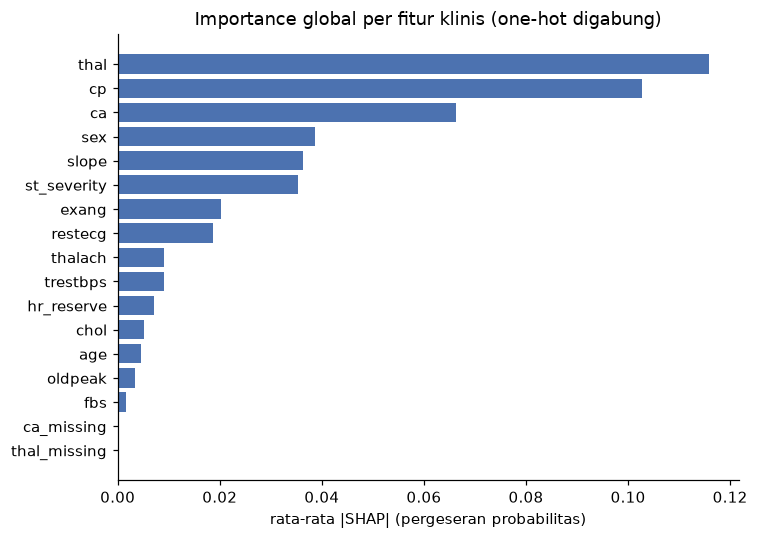

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
top = imp["SHAP ensemble"].iloc[::-1]
ax.barh(top.index, top.values, color="#4C72B0")
ax.set_xlabel("rata-rata |SHAP| (pergeseran probabilitas)")
ax.set_title("Importance global per fitur klinis (one-hot digabung)")
plt.tight_layout(); plt.show()

**Cara membaca:**
- Tiga fitur teratas, yaitu `thal` (tes thallium), `cp` (jenis nyeri dada), dan `ca` (jumlah pembuluh yang terlihat di fluoroskopi), menyumbang ±60% total importance.
  Ketiganya juga masuk 5 besar korelasi di EDA (`thal` peringkat 1, `ca` 2, `cp` 5), dan `ca` + `thal` termasuk fitur yang dipilih GA+CSO di Assignment #2.
  Secara garis besar, model memakai fitur yang memang sudah terlihat kuat sejak EDA.
- Urutan dari KernelSHAP (ensemble) dan TreeSHAP (RF saja) mirip (Spearman 0,81), dan tiga teratasnya identik. Jadi urutan teratas ini bukan artefak aproksimasi KernelSHAP.
- Yang sekilas aneh adalah`oldpeak` (peringkat 14) dan `thalach` (9) jauh lebih rendah daripada di EDA (6 dan 4). Bukan berarti model mengabaikan informasinya.
  Informasinya pindah ke fitur rekayasa: `st_severity = oldpeak × slope` dan `hr_reserve = thalach − (220 − age)`.
  Kalau dijumlah per kelompok, informasi ST/olahraga (oldpeak + st_severity + slope) bernilai 0,072, setara dengan `ca`.
  Jadi membaca importance per kolom tanpa memperhatikan fitur rekayasanya bisa menyesatkan.
- Pada fitur kontinu, kedua explainer berbeda: RF membagi kontribusi cukup rata ke `thalach`, `hr_reserve`, `oldpeak`, `age` (0,024–0,030),
  sedangkan pada ensemble jauh lebih kecil. Karena ensemble = ½ RF + ½ CNN, bagian CNN tampaknya lebih bergantung pada fitur kategorikal/one-hot.
- `sex` naik ke peringkat 4 di SHAP, padahal korelasinya hanya peringkat 10. Model memakai jenis kelamin lebih banyak daripada yang ditunjukkan korelasi linear.
  Secara domain, laki-laki memang berisiko lebih tinggi. Tetapi ini juga cerminan komposisi sampel Cleveland, dengan pasien perempuan sedikit dan kebanyakan sehat (lihat EDA #2).`
  Kalau model dipakai di populasi lain, ketergantungan ini bisa menjadi bias.
- `ca_missing` dan `thal_missing` praktis nol (dibahas di E1).

## C2. Arah pengaruh (beeswarm)

Setiap titik mewakili satu pasien. Posisi horizontal = nilai SHAP (kanan = mendorong ke "sakit"), warna = nilai fitur (merah tinggi, biru rendah).
Warnanya berasal dari nilai setelah preprocessing, tetapi semua transformasi di E5 (log1p, clipping, Min-Max) **monoton**,
jadi tinggi dan rendah tetap berarti sama dengan nilai aslinya. Untuk one-hot warna merah berarti pasien berada di kategori itu.

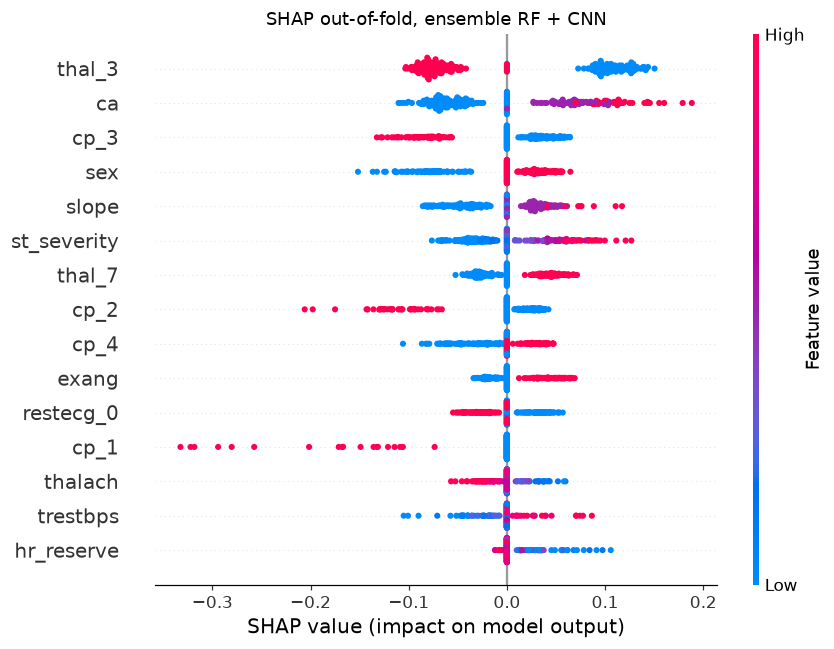

In [17]:
shap.summary_plot(S.values, X_oof.values, feature_names=list(S.columns), max_display=15, show=False, plot_size=(8, 6))
plt.title("SHAP out-of-fold, ensemble RF + CNN"); plt.tight_layout(); plt.show()

In [18]:
# Bukti dari data untuk arah pengaruh cp (jenis nyeri dada), hanya data train
ct = pd.crosstab(R.cp, R[TARGET], margins=True)
ct["% sakit"] = (100 * ct[1] / ct["All"]).round(1)
ct.index = ["1 angina tipikal", "2 angina atipikal", "3 nyeri non-angina", "4 asimtomatik", "total"]
display(ct)

num,0,1,All,% sakit
1 angina tipikal,13,6,19,31.6
2 angina atipikal,35,7,42,16.7
3 nyeri non-angina,49,15,64,23.4
4 asimtomatik,34,83,117,70.9
total,131,111,242,45.9


**Cara membaca:** semua arah pengaruh sesuai dengan heatmap korelasi EDA #2 dan pengetahuan klinis.
- `thal_3` = 1 (hasil tes thallium normal) mendorong kuat ke sehat. Sebaliknya, `thal_7` (cacat reversibel, tanda iskemia) mendorong ke sakit.
- Semakin banyak `ca`, semakin ke arah sakit. Begitu juga `sex` = 1 (laki-laki), `exang` = 1 (angina saat olahraga), `slope` datar/menurun, dan `st_severity` tinggi.
- `thalach` dan `hr_reserve` tinggi (jantung mampu mencapai denyut tinggi) mendorong ke sehat.

Arah-arah ini sama dengan heatmap EDA #2 (r `thalach` = −0,42; `exang` = +0,43; `oldpeak` = +0,42).
*Catatan untuk laporan akhir:* kalimat di laporan #2 bagian 2.3 menulis arah sebaliknya (thalach positif, exang/oldpeak negatif). Angka di heatmap-nya yang benar, dan SHAP mengikuti heatmap.

**Satu perilaku yang tidak intuitif:** `cp_4` (asimtomatik, tanpa nyeri dada) justru mendorong ke **sakit**, sedangkan `cp_1` (angina tipikal, gejala klasik penyakit jantung koroner) mendorong ke **sehat**, sampai −0,33 pada beberapa pasien. Tabel di atas menunjukkan model hanya mengikuti data: di train, 70,9% pasien asimtomatik sakit, sedangkan pasien angina tipikal hanya 31,6%.

Penjelasan yang mungkin adalah *selection bias* pada data Cleveland. Semua pasien ini dirujuk untuk angiografi, jadi pasien tanpa keluhan yang tetap dirujuk biasanya punya alasan kuat lain. Model mempelajari pola rujukan itu, bukan hubungan klinis yang berlaku umum. Ini bukan leakage, tetapi membatasi generalisasi ke populasi umum.
Selain itu, `cp_1` hanya didukung 19 pasien di train.

## C3. Bentuk hubungan untuk fitur kontinu/ordinal teratas

Sumbu x memakai **nilai asli** (bukan nilai terskala) agar mudah dibaca secara klinis

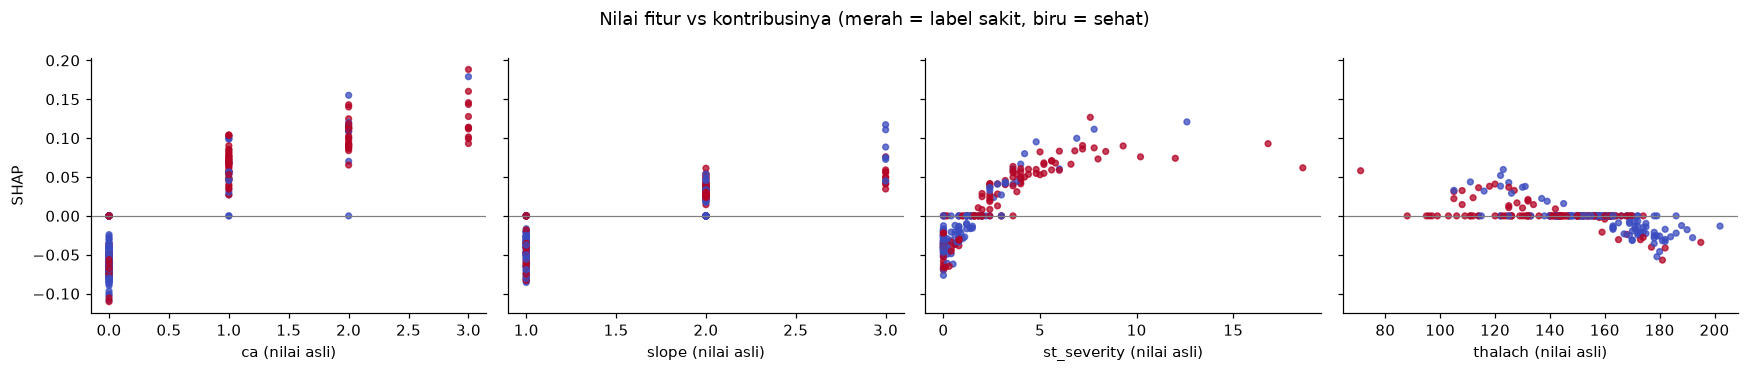

In [19]:
num_feats = [f for f in imp.index if f in continuous_cols + ORDINAL_COLS + ENGINEERED_COLS][:4]
fig, axes = plt.subplots(1, len(num_feats), figsize=(4 * len(num_feats), 3.4), sharey=True)
for ax, f in zip(axes, num_feats):
    ax.scatter(R.loc[S.index, f], S[f], c=R.loc[S.index, TARGET], cmap="coolwarm", s=14, alpha=.75)
    ax.axhline(0, color="grey", lw=.8)
    ax.set_xlabel(f + " (nilai asli)")
axes[0].set_ylabel("SHAP")
fig.suptitle("Nilai fitur vs kontribusinya (merah = label sakit, biru = sehat)")
plt.tight_layout(); plt.show()

**Cara membaca:**
- `ca` berbentuk tangga dengan ca = 0 selalu mendorong ke sehat, dan tiap tambahan pembuluh menaikkan kontribusi (sampai +0,19 pada ca = 3). Model memperlakukan `ca` seperti skor bertingkat, dan itu masuk akal.
- `slope`: 1 (menaik) → sehat, 2–3 → sakit.
- `st_severity` naik tajam dari 0 sampai ±5, lalu mendatar. Nilai ekstrem (sampai 18) tidak menambah pengaruh, karena E5 clip outlier dan RF memang jenuh di ujung. Jadi outlier tidak mendominasi prediksi.
- `thalach` pengaruhnya kecil dan banyak yang dekat nol, karena informasinya terbagi dengan `hr_reserve` (lihat E2).
- Banyak titik tepat di SHAP = 0 (misalnya pada ca = 0 atau slope = 2). Itu **artefak teknis**, bukan tanda fitur tidak berpengaruh.
  `shap.kmeans` membulatkan setiap centroid background ke nilai data asli. Kalau nilai pasien sama dengan nilai di kesepuluh centroid, KernelSHAP menganggap fitur itu tidak berubah dan memberinya nilai  0,   lalu kontribusinya terserap ke fitur lain. Ini dicatat sebagai limitasi (background kecil).

# BAGIAN D | Interpretasi lokal (Instruksi 6)

Lima pasien dipilih dari prediksi out-of-fold dengan aturan tetap:

| Kasus | Aturan |
|---|---|
| TP yakin | label 1, diprediksi 1, probabilitas tertinggi |
| TN yakin | label 0, diprediksi 0, probabilitas terendah |
| FN terparah | label 1, diprediksi 0, probabilitas terendah |
| FP terparah | label 0, diprediksi 1, probabilitas tertinggi |
| Paling ragu | probabilitas paling dekat 0,5 |

Grafik *waterfall* dibaca dari bawah ke atas, dimulai dari base value (rata-rata prediksi), tiap batang menambah (merah) atau mengurangi (biru) probabilitas, sampai ke prediksi akhir pasien. Label di kiri memakai nilai asli, sedangkan `cp_4 = 1` berarti pasien berada di kategori cp = 4.

In [ ]:
def pick(mask, by, asc):
    return info[mask].sort_values(by, ascending=asc).index[0]

cases = {
    "TP yakin":    pick((info.y == 1) & (info.pred == 1), "prob", False),
    "TN yakin":    pick((info.y == 0) & (info.pred == 0), "prob", True),
    "FN terparah": pick((info.y == 1) & (info.pred == 0), "prob", True),
    "FP terparah": pick((info.y == 0) & (info.pred == 1), "prob", False),
    "Paling ragu": (info.prob - .5).abs().idxmin(),
}

# Nilai yang ditampilkan adalah nilai asli bila ada, selain itu nilai fitur hasil preprocessing (one-hot / flag 0-1)
D = X_oof.copy()
for c in D.columns:
    if c in R.columns:
        D[c] = R.loc[D.index, c]

raw_cols = continuous_cols + categorical_cols + [TARGET]
case_tbl = R.loc[list(cases.values()), raw_cols].copy()
case_tbl.insert(0, "kasus", list(cases.keys()))
case_tbl["prob"] = info.loc[case_tbl.index, "prob"].round(3)
case_tbl["rf_prob"] = info.loc[case_tbl.index, "rf_prob"].round(3)
case_tbl["cnn_prob"] = info.loc[case_tbl.index, "cnn_prob"].round(3)
med = R.groupby(TARGET)[continuous_cols + categorical_cols].median()
med.index = ["median sehat (0)", "median sakit (1)"]
display(case_tbl)
display(med)

,kasus,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,num,prob,rf_prob,cnn_prob
row_id,,,,,,,,,,,,,,,,,,
126,TP yakin,56.0,200.0,288.0,133.0,4.0,0.0,4.0,1.0,2.0,1.0,3.0,2.0,7.0,1,0.993,0.990,0.997
238,TN yakin,49.0,134.0,271.0,162.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0,3.0,0,0.012,0.015,0.009
145,FN terparah,47.0,108.0,243.0,152.0,0.0,1.0,3.0,0.0,0.0,0.0,1.0,0.0,3.0,1,0.055,0.077,0.033
252,FP terparah,64.0,128.0,263.0,105.0,0.2,1.0,4.0,0.0,0.0,1.0,2.0,1.0,7.0,0,0.938,0.918,0.958
183,Paling ragu,59.0,178.0,270.0,145.0,4.2,1.0,1.0,0.0,2.0,0.0,3.0,0.0,7.0,0,0.510,0.624,0.395


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal
median sehat (0),52.0,129.0,240.0,161.0,0.2,1.0,3.0,0.0,0.0,0.0,1.0,0.0,3.0
median sakit (1),58.0,130.0,254.0,142.0,1.2,1.0,4.0,0.0,2.0,1.0,2.0,1.0,7.0


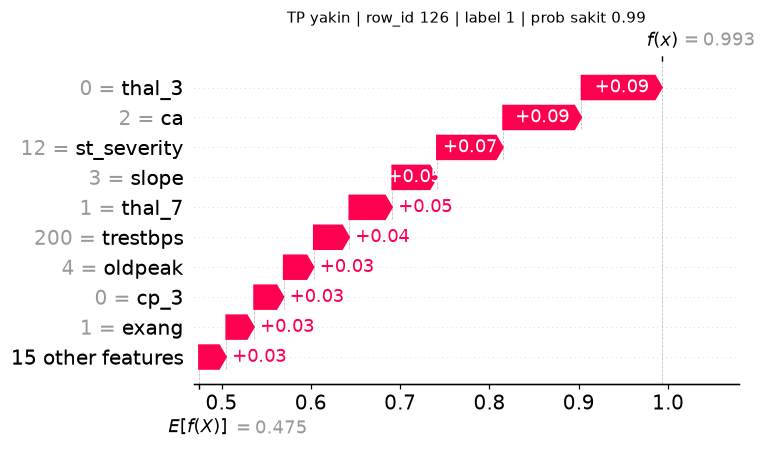

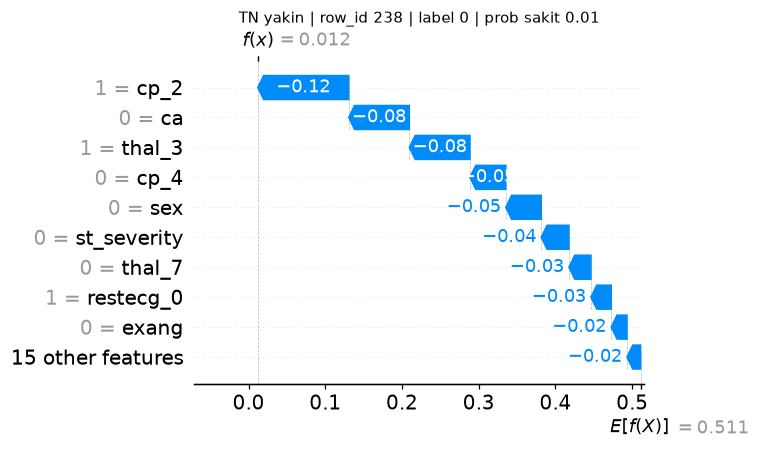

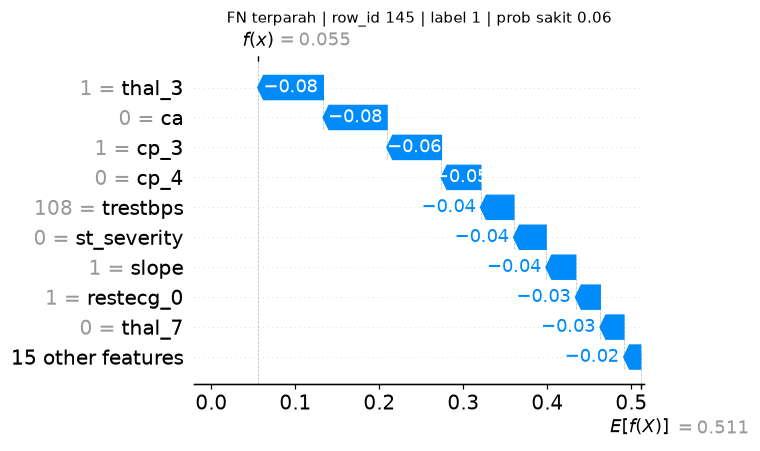

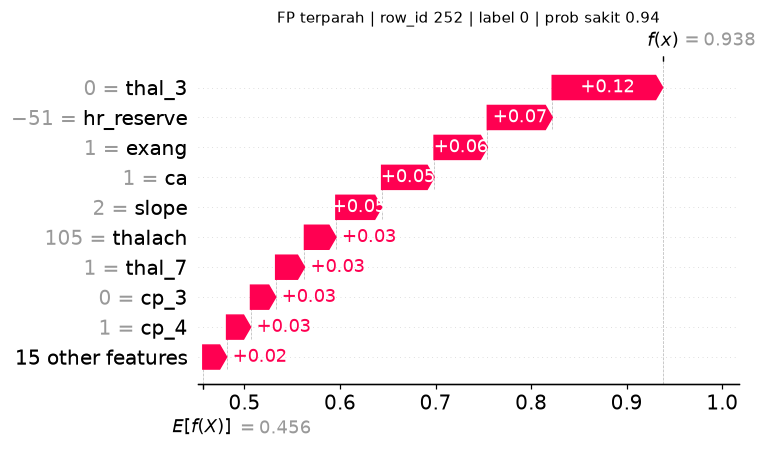

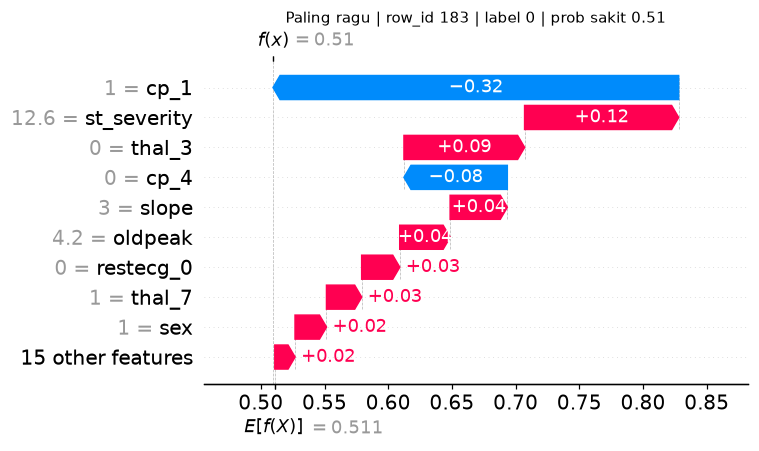

In [21]:
for name, rid in cases.items():
    e = shap.Explanation(values=S.loc[rid].values, base_values=info.loc[rid, "base"],
                         data=D.loc[rid].values, feature_names=list(S.columns))
    shap.plots.waterfall(e, max_display=10, show=False)
    plt.gcf().set_size_inches(7, 4.2)
    plt.title(f"{name} | row_id {rid} | label {info.loc[rid, 'y']} | prob sakit {info.loc[rid, 'prob']:.2f}", fontsize=10)
    plt.tight_layout(); plt.show()

**Cara membaca per kasus** (bandingkan dengan tabel nilai mentah dan median kelas di atas):

- **TP yakin (row 126, prob 0,99).** Hampir semua penanda sakit muncul bersamaan: thallium tidak normal (`thal` = 7), 2 pembuluh di fluoroskopi, oldpeak 4 dengan slope menurun (`st_severity` = 12), dan angina saat olahraga. Tidak ada satu fitur pun yang mendorong ke sehat. Ini kasus "mudah".
- **TN yakin (row 238, prob 0,01).** Kebalikannya: angina atipikal (`cp_2`), ca = 0, thallium normal, perempuan, dan tanpa depresi ST.
- **FN terparah (row 145, label sakit, prob 0,06).** Laki-laki 47 tahun dengan nyeri non-angina, thallium normal, ca = 0, oldpeak 0, slope menaik, dan denyut maksimum 152.
  Hampir semua nilainya sama dengan **median pasien sehat**. Tidak ada fitur yang "salah dibaca" model: memang begitulah biasanya profil orang sehat.
  Jadi pertanyaannya bukan "kenapa modelnya salah", melainkan "apa yang membuat pasien ini berlabel sakit padahal fiturnya tidak menunjukkannya?". Kandidat jawabannya adalah label (binarisasi `num` 1–4 → 1; penyakit ringan bisa saja tanpa tanda) atau fitur penting yang tidak ada di dataset. Ini diteruskan ke review Cleanlab dan dibahas di E4–E5.
- **FP terparah (row 252, label sehat, prob 0,94).** Laki-laki 64 tahun, asimtomatik, angina saat olahraga, thallium cacat reversibel, ca = 1, dan denyut maksimum hanya 105 (`hr_reserve` = −51). Secara fitur ia mirip pasien sakit. Polanya kebalikan dari FN: penanda sakitnya ada, tetapi labelnya sehat.
- **Paling ragu (row 183, prob 0,51, label sehat).** Ada tarik-menarik yang jelas. `cp_1` (angina tipikal) mendorong −0,32 ke sehat, sementara oldpeak 4,2 dengan slope menurun (`st_severity` = 12,6) dan thallium tidak normal mendorong ke sakit. Keputusan akhirnya ditentukan oleh selisih tipis, dan RF (0,62) serta CNN (0,40) tidak sepakat.
  Kasus ini juga memperlihatkan betapa besarnya bobot `cp_1` (lihat C2), padahal fitur itu hanya didukung 19 pasien.

## D2. LIME sebagai pembanding

LIME bekerja lain, dengan cara membuat ribuan pasien tiruan di sekitar satu pasien (nilai fitur diacak dari distribusi data latih), model ditanya prediksinya, lalu dipasang model linear sederhana yang hanya berlaku di sekitar pasien itu. Bobot model linear itulah penjelasannya. Fitur kontinu dipecah ke kuartil, sehingga keluarannya berbentuk aturan seperti `thalach <= 0.55`. Angka di aturan LIME adalah nilai **setelah Min-Max**, bukan nilai asli. Itu salah satu kelemahan praktis LIME di pipeline ini.

Dua hal diperiksa:
1. **Kesepakatan**: dari 5 fitur teratas SHAP, berapa yang juga ada di 5 teratas LIME?
2. **Stabilitas**: LIME diulang dengan 5 seed berbeda. Rata-rata irisan top-5 antar-seed (Jaccard) menunjukkan seberapa konsisten LIME dengan dirinya sendiri.

In [22]:
CAT_IDX = lambda feats: [i for i, f in enumerate(feats) if f in BINARY_COLS or f.endswith("_missing") or parent(f) != f]

def lime_top(rid, seed, k=5):
    fm = fold_models[fold_of[rid]]
    ex = lime.lime_tabular.LimeTabularExplainer(
        fm["X_tr"], feature_names=fm["feats"], class_names=["sehat", "sakit"], mode="classification",
        categorical_features=CAT_IDX(fm["feats"]), discretize_continuous=True, random_state=seed)
    proba = lambda Z: (lambda p: np.c_[1 - p, p])(fm["f"](Z))
    x = X_oof.loc[rid, fm["feats"]].values
    e = ex.explain_instance(x, proba, num_features=k, num_samples=2000)
    pairs = e.as_list(label=1)
    names = [fm["feats"][i] for i, _ in e.as_map()[1]]
    return names, pairs

rows, jac = [], {}
for name, rid in cases.items():
    shap_top = list(S.loc[rid].abs().sort_values(ascending=False).index[:5])
    tops = [lime_top(rid, s) for s in range(5)]
    lime_names, lime_rules = tops[0]
    sets = [set(t[0]) for t in tops]
    jac[name] = np.mean([len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i + 1:]])
    rows.append({"kasus": name, "row_id": rid, "top-5 SHAP": ", ".join(shap_top),
                 "top-5 LIME (seed 0)": "; ".join(f"{r} ({w:+.2f})" for r, w in lime_rules),
                 "irisan SHAP∩LIME": len(set(shap_top) & set(lime_names)),
                 "stabilitas LIME (Jaccard)": round(jac[name], 2)})
lime_tbl = pd.DataFrame(rows).set_index("kasus")
with pd.option_context("display.max_colwidth", None):
    display(lime_tbl)

,row_id,top-5 SHAP,top-5 LIME (seed 0),irisan SHAP∩LIME,stabilitas LIME (Jaccard)
kasus,,,,,
TP yakin,126,"thal_3, ca, st_severity, slope, thal_7",thal_3=0 (+0.20); ca > 0.33 (+0.20); cp_3=0 (+0.16); cp_2=0 (+0.14); sex=0 (-0.12),2,0.80
TN yakin,238,"cp_2, ca, thal_3, cp_4, sex",cp_1=0 (+0.23); thal_3=1 (-0.19); cp_2=1 (-0.18); ca <= 0.00 (-0.17); sex=0 (-0.11),4,1.00
FN terparah,145,"thal_3, ca, cp_3, cp_4, trestbps",cp_1=0 (+0.23); thal_3=1 (-0.19); cp_2=0 (+0.18); ca <= 0.00 (-0.17); sex=1 (+0.11),2,1.00
FP terparah,252,"thal_3, hr_reserve, exang, ca, slope",thal_3=0 (+0.20); cp_3=0 (+0.13); sex=1 (+0.13); cp_2=0 (+0.12); restecg_0=1 (-0.08),1,0.87
Paling ragu,183,"cp_1, st_severity, thal_3, cp_4, slope",cp_1=1 (-0.24); thal_3=0 (+0.19); cp_2=0 (+0.19); ca <= 0.00 (-0.17); st_severity > 0.40 (+0.14),3,0.87


**Cara membaca:**
- Untuk faktor utama, LIME dan SHAP sepakat: `thal_3`, `ca`, jenis nyeri dada (`cp_*`), dan `sex` selalu muncul di keduanya. Irisan top-5 berkisar 1–4 dari 5.
- Perbedaannya ada pada *apa yang dijelaskan*. SHAP membandingkan pasien dengan rata-rata (base value) dan jumlahnya tepat sama dengan prediksi. LIME memasang garis lurus di sekitar pasien memakai sampel tiruan yang diambil dari distribusi seluruh data latih. Akibatnya LIME memberi `cp_1=0 (+0.23)` untuk pasien TN maupun FN, yang berarti pasien ini bukan angina tipikal, dan itu menaikkan risiko. Itu benar secara rata-rata, tetapi bukan alasan pasien TN tersebut diprediksi sehat. Untuk menjelaskan satu pasien, waterfall SHAP lebih mudah dipertanggungjawabkan.
- Stabilitas LIME antar-seed cukup baik (Jaccard 0,80–1,00 dengan 2000 sampel). Jadi perbedaannya dengan SHAP bukan karena LIME acak, melainkan karena definisi penjelasannya berbeda.
- Ambang aturan LIME (`ca > 0.33`, `st_severity > 0.40`) ada di skala Min-Max, sehingga tidak bisa langsung dibaca secara klinis.

Karena itu SHAP dipakai sebagai penjelasan utama, dan LIME sebagai cek silang bahwa faktor-faktor utamanya sama.

# BAGIAN E | Menghubungkan interpretasi ke kualitas data (Instruksi 7)

Anggota 1 menitipkan dua temuan untuk dicek lewat SHAP (tabel C6 di notebooknya, nomor 3 dan 4):
1. fitur yang hanya didukung 1–2 baris (`ca_missing`, `thal_missing`, `restecg_1`);
2. `hr_reserve` yang merupakan kombinasi linear persis dari `thalach` dan `age`.

Setelah itu dicek kemungkinan leakage, lalu semua salah prediksi ditelusuri sumbernya: **data → label → fitur → model**.

## E1. Fitur yang didukung sangat sedikit baris

In [ ]:
rare = ["ca_missing", "thal_missing", "restecg_1"]
rare_mask = {"ca_missing": R.ca.isna(), "thal_missing": R.thal.isna(), "restecg_1": R.restecg == 1}
rank_all = S.abs().mean().rank(ascending=False).astype(int)

def n_seen(f, k):
    # berapa baris bernilai 1 untuk fitur f di data latih fold k (0 kalau kolomnya bahkan tidak terbentuk)
    feats = fold_models[k]["feats"]
    return int((fold_models[k]["X_tr"][:, feats.index(f)] == 1).sum()) if f in feats else 0

display(pd.DataFrame({
    "baris di seluruh train": {f: int(rare_mask[f].sum()) for f in rare},
    "rata-rata |SHAP| semua pasien": {f: S[f].abs().mean() for f in rare},
    f"rank dari {S.shape[1]} fitur": {f: rank_all[f] for f in rare}}).round(4))

rows = []
for f in rare:
    for rid in R.index[rare_mask[f]]:
        k = fold_of[rid]
        rows.append({"fitur": f, "row_id": rid, "label": info.loc[rid, "y"], "prob": info.loc[rid, "prob"],
                     "baris =1 di train fold": n_seen(f, k),
                     "SHAP ensemble": S.loc[rid, f], "SHAP RF (tree)": S_rf.loc[rid, f]})
display(pd.DataFrame(rows).set_index(["fitur", "row_id"]).round(3))

,baris di seluruh train,rata-rata |SHAP| semua pasien,rank dari 24 fitur
ca_missing,1,0.0002,22
thal_missing,1,0.0001,23
restecg_1,1,0.0000,24


,,label,prob,baris =1 di train fold,SHAP ensemble,SHAP RF (tree)
fitur,row_id,,,,,
ca_missing,192,1,0.711,0,-0.060,0.0
thal_missing,266,1,0.288,0,-0.023,0.0
restecg_1,257,0,0.152,0,0.000,0.0


**Cara membaca:** masing-masing fitur ini hanya punya **1 pasien** di seluruh data train. Kolom `baris =1 di train fold` = 0 menunjukkan konsekuensi yang lebih mendasar yaitu setiap kali pasien itu diprediksi (out-of-fold), model **belum pernah melihat** nilai 1 pada fitur tersebut, karena satu-satunya contohnya adalah pasien itu sendiri. Untuk `restecg_1`, kolomnya bahkan tidak terbentuk di fold itu (itulah sebabnya fold 3 hanya punya 23 fitur di B2).

Yang tetap terjadi:
- RF memberi SHAP 0 untuk ketiganya. Masuk akal, karena pohon tidak pernah membuat split di kolom yang selalu bernilai 0.
- Ensemble tetap memberi −0,060 (`ca_missing`, row 192) dan −0,023 (`thal_missing`, row 266). Kontribusi ini sepenuhnya berasal dari **CNN**.
  Conv1D memakai kernel yang sama di semua posisi fitur, sehingga nilai 1 di posisi yang tidak pernah aktif saat training tetap menghasilkan respons.
  Angka itu efek samping arsitektur, bukan pola yang dipelajari dari data.

**Temuan yang lebih penting justru ada di imputasi.** Pasien 192 (`ca` kosong) dan 266 (`thal` kosong) sama-sama berlabel sakit. Nilai kosongnya diisi modus, yaitu `ca` = 0 dan `thal` = 3 (normal), dua nilai yang paling "sehat". Di tabel E4, pendorong utama pasien 266 ke arah sehat adalah `thal_3=1 (-0.09)`. Itu **nilai hasil imputasi**, bukan hasil tes sungguhan, dan pasien 266 akhirnya menjadi false negative. Imputasi modus pada fitur diagnostik secara sistematis mengisi "hasil tes normal", sehingga untuk pasien sakit yang datanya kosong, model terdorong ke arah yang salah. Jumlahnya hanya 2 pasien, jadi dampaknya ke metrik kecil. Tetapi ini contoh nyata masalah data yang baru kelihatan lewat penjelasan model.

Kesimpulan: ketiga fitur langka tidak bisa dipelajari dan tidak berperan dalam prediksi, dan flag missing tidak menolong pasien yang datanya kosong. Uji ablasi di E2 menunjukkan bahwa membuangnya tidak menurunkan performa.

## E2. `hr_reserve`: redundansi dan pembagian kontribusi

In [24]:
trio = ["thalach", "age", "hr_reserve"]
print("Rata-rata |SHAP|:", S[trio].abs().mean().round(4).to_dict())
print("Rata-rata |SHAP| jika ketiganya dijumlah per pasien:", round(S[trio].sum(axis=1).abs().mean(), 4))
print("Korelasi nilai SHAP thalach vs hr_reserve antar-pasien:", round(S.thalach.corr(S.hr_reserve), 3))
print("Korelasi nilai fitur (setelah preprocessing) thalach vs hr_reserve:", round(X_oof.thalach.corr(X_oof.hr_reserve), 3))

Rata-rata |SHAP|: {'thalach': 0.0092, 'age': 0.0047, 'hr_reserve': 0.007}
Rata-rata |SHAP| jika ketiganya dijumlah per pasien: 0.0207
Korelasi nilai SHAP thalach vs hr_reserve antar-pasien: 0.656
Korelasi nilai fitur (setelah preprocessing) thalach vs hr_reserve: 0.921


**Cara membaca:** `hr_reserve` dan `thalach` berkorelasi 0,92 (setelah preprocessing), dan nilai SHAP keduanya ikut bergerak bersama antar-pasien (korelasi 0,66). Kontribusi "denyut jantung" jadi terbagi ke tiga kolom (0,009 + 0,005 + 0,007). Kalau dijumlah per pasien hasilnya 0,021, tetap hanya ±4% dari total. Ini efek asumsi independensi KernelSHAP: informasi yang sama dipecah sehingga tiap kolom tampak lebih kecil daripada pengaruh informasinya. Di laporan, importance `thalach` sebaiknya dibaca bersama `hr_reserve`.

**Uji ablasi.** SHAP hanya memberi tahu seberapa besar model *memakai* sebuah fitur, bukan apakah fitur itu *perlu*. Ada tiga uji: tanpa `hr_reserve`, tanpa fitur langka dari E1, dan tanpa `ca` + `thal` (untuk cek leakage di E3). Untuk menjawab yang kedua, model dilatih ulang tanpa fitur tersebut dengan fold, model, dan metrik yang sama (`evaluate_cv`, 15 fold), lalu dibandingkan berpasangan per fold dengan E5 yang dijalankan ulang di mesin ini (TensorFlow bisa sedikit berbeda antar-mesin, jadi pembandingnya harus dari mesin yang sama).

Ini **uji diagnostik**, bukan usulan mengganti pipeline. Soal meminta model dan prosedur dijaga konsisten agar efek perubahan data bisa diukur.

 Hasilnya ditulis ke file terpisah (`artifacts/anggota4/cv_ablation.csv`) agar `cv_results.csv` milik bersama tidak tercampur.

In [25]:
def drop_features(preprocess_fn, cols):
    def f(tr_df, ev_df):
        X_tr, y_tr, X_ev, names = preprocess_fn(tr_df, ev_df)
        keep = [i for i, n in enumerate(names) if n not in cols]
        return np.asarray(X_tr)[:, keep], y_tr, np.asarray(X_ev)[:, keep], [names[i] for i in keep]
    return f

ABL_CSV = f"{OUT_DIR}/cv_ablation.csv"
ablasi = {
    "E5_ulang":          PREPROCESS_FN,
    "tanpa_hr_reserve":  drop_features(PREPROCESS_FN, ["hr_reserve"]),
    "tanpa_fitur_langka": drop_features(PREPROCESS_FN, rare),
    "tanpa_ca_thal":     drop_features(PREPROCESS_FN, [f for f in ALL_FEATS if f.startswith(("ca", "thal_"))]),
}
for code_, pp in ablasi.items():
    t0 = time.time()
    evaluate_cv(code_, train_df, pp, results_csv=ABL_CSV, verbose=False, **DATA_KW)
    print(f"{code_:20s} selesai ({time.time() - t0:.0f} detik)")

display(summarize(ABL_CSV))
for code_ in list(ablasi)[1:]:
    print(f"{code_:20s} - E5_ulang (macro F1):", paired_delta("E5_ulang", code_, results_csv=ABL_CSV))

E5_ulang             selesai (140 detik)


tanpa_hr_reserve     selesai (143 detik)


tanpa_fitur_langka   selesai (137 detik)


tanpa_ca_thal        selesai (138 detik)


accuracy         macro_f1         balanced_acc          \
                       mean     std     mean     std         mean     std   
exp                                                                         
tanpa_fitur_langka   0.8128  0.0576   0.8087  0.0603       0.8078  0.0591   
tanpa_hr_reserve     0.8127  0.0559   0.8079  0.0593       0.8070  0.0577   
E5_ulang             0.8074  0.0601   0.8028  0.0632       0.8021  0.0616   
tanpa_ca_thal        0.7535  0.0633   0.7500  0.0648       0.7504  0.0644   

                       mcc         roc_auc          pr_auc          
                      mean     std    mean     std    mean     std  
exp                                                                 
tanpa_fitur_langka  0.6265  0.1152  0.8869  0.0509  0.8912  0.0507  
tanpa_hr_reserve    0.6271  0.1097  0.8905  0.0502  0.8944  0.0501  
E5_ulang            0.6161  0.1196  0.8903  0.0478  0.8960  0.0471  
tanpa_ca_thal       0.5061  0.1291  0.8332  0.0594  0.8299  0.0562

tanpa_hr_reserve     - E5_ulang (macro F1): {'delta_mean': np.float64(0.0051), 'delta_std': np.float64(0.0284), 'menang': 8, 'kalah': 4, 'seri': 3}
tanpa_fitur_langka   - E5_ulang (macro F1): {'delta_mean': np.float64(0.0059), 'delta_std': np.float64(0.0181), 'menang': 5, 'kalah': 2, 'seri': 8}
tanpa_ca_thal        - E5_ulang (macro F1): {'delta_mean': np.float64(-0.0528), 'delta_std': np.float64(0.0576), 'menang': 4, 'kalah': 11, 'seri': 0}


**Cara membaca:** E5 yang dijalankan ulang di mesin ini menghasilkan macro F1 0,803 ± 0,063, sama persis dengan angka Thufail. Kerangkanya reproducible.

| Uji | Δ macro F1 vs E5 (berpasangan) | Menang / kalah / seri | Arti |
|---|---|---|---|
| tanpa `hr_reserve` | +0,005 ± 0,028 | 8 / 4 / 3 | jauh di bawah noise; fitur ini tidak menambah informasi |
| tanpa fitur langka | +0,006 ± 0,018 | 5 / 2 / 8 | sama; tidak berguna, membuangnya tidak merugikan |
| tanpa `ca` dan `thal` | **−0,053** ± 0,058 | 4 / **11** / 0 | turun jelas; MCC 0,616 → 0,506, ROC-AUC 0,890 → 0,833 |

Dua uji pertama mengonfirmasi bacaan SHAP: `hr_reserve` dan flag langka tidak membawa informasi baru. Meski begitu, pipeline **tidak diubah**. Kenaikannya di bawah noise, dan soal meminta model serta prosedur dijaga tetap agar perbandingan D0–D3 adil. Ini dicatat sebagai rekomendasi untuk pipeline berikutnya.

Uji ketiga menunjukkan model **sangat bergantung** pada `ca` dan `thal`, sesuai dengan SHAP (±38% importance). Apakah itu masalah, dibahas di E3.

## E3. Cek kemungkinan data leakage

Leakage berarti ada fitur yang membawa informasi tentang target yang **tidak tersedia secara wajar saat prediksi**, misalnya fitur turunan dari diagnosis itu sendiri. Tanda-tandanya di SHAP biasanya satu fitur yang mendominasi secara ekstrem, atau satu fitur yang sendirian hampir sempurna memisahkan kelas. Keduanya diperiksa di sini (data train saja).

In [26]:
from sklearn.metrics import roc_auc_score
single = {}
for c in continuous_cols + categorical_cols + ENGINEERED_COLS:
    v = R[c].fillna(R[c].median())
    a = roc_auc_score(R[TARGET], v)
    single[c] = max(a, 1 - a)
single = pd.Series(single, name="AUC satu fitur").sort_values(ascending=False)
display(single.round(3).to_frame().T)
print(f"Porsi importance fitur teratas ({imp.index[0]}): {imp['share %'].iloc[0]:.1f}% dari total")
print(f"Porsi 3 fitur teratas: {imp['share %'].iloc[:3].sum():.1f}%")

,thal,cp,thalach,ca,st_severity,oldpeak,exang,hr_reserve,slope,sex,age,restecg,trestbps,chol,fbs
AUC satu fitur,0.775,0.743,0.737,0.736,0.735,0.721,0.698,0.692,0.68,0.644,0.627,0.581,0.572,0.568,0.516


Porsi importance fitur teratas (thal): 24.4% dari total
Porsi 3 fitur teratas: 60.1%


**Cara membaca:** secara statistik tidak ada tanda leakage klasik. Fitur terkuat pun, kalau dipakai sendirian, hanya mencapai AUC 0,775 (`thal`); tidak ada yang mendekati 1.
Importance juga tidak dimonopoli satu fitur (fitur teratas 24%).

Tetapi ada pertanyaan **kontekstual** yang perlu masuk laporan. Menurut dokumentasi UCI, target `num` adalah *angiographic disease status*
(penyempitan > 50% pada pembuluh koroner berdasarkan angiografi), sedangkan `ca` adalah jumlah pembuluh utama yang terlihat dengan fluoroskopi.
Kalau `ca` diambil dari prosedur kateterisasi/angiografi yang sama, maka `ca` adalah bagian dari proses yang **menentukan label**, bukan informasi yang tersedia sebelum diagnosis. Hal serupa, dalam kadar lebih ringan, berlaku untuk `thal` (tes thallium), yang juga termasuk pemeriksaan lanjutan. Dokumentasi dataset tidak menjelaskan kapan `ca` diukur, jadi ini **tidak bisa dipastikan**. Status yang jujur adalah "kemungkinan target leakage secara konteks".

Implikasinya, model ini valid sebagai alat bantu untuk pasien yang **sudah** menjalani pemeriksaan lanjutan, bukan untuk skrining awal.
Uji ablasi E2 mengukur seberapa besar ketergantungannya: tanpa `ca` dan `thal`, macro F1 turun ±0,05 (kalah di 11 dari 15 fold).
Kedua fitur tetap dipertahankan karena (1) tidak ada bukti bahwa `ca` diukur bersamaan dengan label, (2) Assignment #2–#3 dan paper acuan juga memakainya, dan (3) soal melarang mengganti model/fitur dalam perbandingan data. Tetapi poin ini wajib masuk bagian limitasi.

## E4. Menelusuri semua salah prediksi: data → label → fitur → model

Untuk setiap pasien yang salah diprediksi (out-of-fold, repeat 0), dikumpulkan bukti berikut:

| Kolom | Arti |
|---|---|
| `p_label` | probabilitas model untuk label yang tercatat. Ini sama dengan skor *self-confidence* yang dipakai Cleanlab. Makin kecil, makin "tidak cocok" label dengan fiturnya |
| `salah_3_repeat` | apakah pasien ini juga salah pada rata-rata 3 repeat (`oof_baseline.csv` Thufail). Kalau ya, kesalahannya stabil, bukan kebetulan pembagian fold |
| `rf_vs_cnn` | apakah RF dan CNN tidak sepakat |
| `imputasi/outlier` | apakah `ca`/`thal` pasien ini kosong (diimputasi), atau ada nilai kontinu di luar batas IQR (di-clip) |
| `pendorong` | 3 fitur dengan SHAP terbesar ke arah kelas yang salah |

Kolom `indikasi` diisi dengan aturan berurutan sesuai alur di soal. Aturan pertama yang cocok yang dipakai:
1. **data**: nilai pasien diimputasi atau di-clip (record-nya sendiri tidak utuh);
2. **label?**: model yakin label salah (`p_label < 0,2`) dan kesalahannya stabil di 3 repeat. Ini kandidat untuk direview Marco, **bukan** bukti label salah;
3. **fitur**: salah satu pendorong utama adalah fitur langka dari E1;
4. **model**: RF dan CNN tidak sepakat;
5. **ambigu**: probabilitas di 0,35–0,65, pasien memang di daerah perbatasan;
6. **atipikal**: model cukup yakin tapi salah, dan tidak ada penjelasan dari 1–5. Pola pasien berbeda dari mayoritas kelasnya.

Kolom ini adalah **indikasi awal untuk diskusi**, bukan keputusan.

In [ ]:
q1, q3 = R[continuous_cols].quantile(.25), R[continuous_cols].quantile(.75)
is_outlier = ((R[continuous_cols] < q1 - 1.5 * (q3 - q1)) | (R[continuous_cols] > q3 + 1.5 * (q3 - q1))).any(axis=1)
is_imputed = R[["ca", "thal"]].isna().any(axis=1)
wrong_3rep = oof_b.set_index("row_id").pipe(lambda d: (d.prob >= .5).astype(int) != d.y)

def indikasi(r):
    if r["imputasi/outlier"]:                      return "data"
    if r.p_label < .2 and r.salah_3_repeat:        return "label? (ke Anggota 3)"
    if any(p.split("=")[0] in rare for p in r.pendorong.split(", ")): return "fitur"
    if r.rf_vs_cnn:                                return "model"
    if .35 <= r.prob <= .65:                       return "ambigu"
    return "atipikal"

wrong = info[info.pred != info.y].copy()
wrong["jenis"] = np.where(wrong.y == 1, "FN", "FP")
wrong["p_label"] = np.where(wrong.y == 1, wrong.prob, 1 - wrong.prob)
wrong["salah_3_repeat"] = wrong_3rep.reindex(wrong.index).values
wrong["rf_vs_cnn"] = (wrong.rf_prob >= .5) != (wrong.cnn_prob >= .5)
wrong["imputasi/outlier"] = (is_imputed | is_outlier).reindex(wrong.index).values
sign = np.where(wrong.pred == 1, 1, -1)[:, None]  # arah kelas yang salah diprediksi
toward = pd.DataFrame(S.loc[wrong.index].values * sign, index=wrong.index, columns=S.columns)
fv = lambda v: "NaN" if pd.isna(v) else (f"{v:.0f}" if float(v).is_integer() else f"{v:.1f}")
wrong["pendorong"] = [", ".join(f"{f}={fv(D.loc[i, f])} ({S.loc[i, f]:+.2f})" for f in toward.loc[i].nlargest(3).index)
                      for i in wrong.index]
wrong["indikasi"] = wrong.apply(indikasi, axis=1)

cols = ["jenis", "prob", "p_label", "salah_3_repeat", "rf_vs_cnn", "imputasi/outlier", "pendorong", "indikasi"]
wrong = wrong.sort_values(["jenis", "p_label"])
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(wrong[cols].round(3))
print("Jumlah per indikasi:", wrong.indikasi.value_counts().to_dict())
print("Jumlah per jenis   :", wrong.jenis.value_counts().to_dict())
wrong[cols].to_csv(f"{OUT_DIR}/salah_prediksi.csv")

,jenis,prob,p_label,salah_3_repeat,rf_vs_cnn,imputasi/outlier,pendorong,indikasi
row_id,,,,,,,,
145,FN,0.055,0.055,True,False,False,"thal_3=1 (-0.08), ca=0 (-0.08), cp_3=1 (-0.06)",label? (ke Anggota 3)
32,FN,0.097,0.097,True,False,False,"cp_3=1 (-0.09), slope=1 (-0.07), thal_3=1 (-0.06)",label? (ke Anggota 3)
22,FN,0.138,0.138,True,False,False,"cp_2=1 (-0.11), thal_3=1 (-0.07), ca=0 (-0.05)",label? (ke Anggota 3)
199,FN,0.156,0.156,True,False,False,"cp_1=1 (-0.20), ca=0 (-0.07), cp_4=0 (-0.06)",label? (ke Anggota 3)
301,FN,0.161,0.161,True,False,False,"cp_2=1 (-0.12), sex=0 (-0.10), thal_3=1 (-0.08)",label? (ke Anggota 3)
232,FN,0.165,0.165,True,False,False,"cp_3=1 (-0.10), thal_3=1 (-0.09), chol=149 (-0.08)",label? (ke Anggota 3)
278,FN,0.166,0.166,True,False,False,"cp_2=1 (-0.18), cp_4=0 (-0.09), thal_3=1 (-0.07)",label? (ke Anggota 3)
261,FN,0.167,0.167,True,False,False,"cp_2=1 (-0.09), sex=0 (-0.08), thal_3=1 (-0.07)",label? (ke Anggota 3)
141,FN,0.178,0.178,True,False,False,"cp_1=1 (-0.32), cp_4=0 (-0.08), ca=0 (-0.08)",label? (ke Anggota 3)


Jumlah per indikasi: {'label? (ke Anggota 3)': 13, 'atipikal': 13, 'model': 10, 'ambigu': 6, 'data': 4}
Jumlah per jenis   : {'FN': 29, 'FP': 17}


**Cara membaca:**
- Ada 46 salah prediksi (29 FN, 17 FP), dan **43 di antaranya juga salah pada rata-rata 3 repeat**. Kesalahannya sistematis: pasien yang sama selalu salah, tidak tergantung pembagian fold. Ini ciri kesalahan yang berasal dari data/label, bukan dari kebetulan.
- Pendorong kesalahan hampir selalu fitur-fitur teratas yang sama (`cp`, `thal_3`, `ca`, `sex`). Tidak ada kesalahan yang disebabkan fitur langka (indikasi "fitur" = 0). Model salah karena fitur utamanya "menunjuk ke arah yang salah" untuk pasien tersebut.
- **13 pasien "label?"** (10 FN, 3 FP): model sangat yakin (`p_label` < 0,2) bahwa fitur pasien cocok dengan kelas lawan, dan hal itu konsisten di 3 repeat. `p_label` adalah skor *self-confidence* yang juga dipakai Cleanlab, jadi daftar ini kemungkinan besar beririsan dengan temuan Anggota 3. Ini **bukan** bukti label salah (soal: *a difference between the model prediction and the original label is not sufficient evidence*), melainkan bahan tambahan untuk review mereka. Daftar lengkapnya tersimpan di `artifacts/anggota4/salah_prediksi.csv`.
- **4 "data"**: pasien dengan nilai diimputasi atau di-clip. Pasien 266 sudah dibahas di E1 (imputasi `thal` = normal menjadi pendorong utama ke arah yang salah).
- **10 "model"** dan **6 "ambigu"**: probabilitas dekat 0,5 atau RF dan CNN tidak sepakat. Pasien-pasien ini memang di daerah perbatasan, tanpa indikasi masalah data.
- **13 "atipikal"**: model cukup yakin tetapi salah, tanpa penjelasan dari kategori lain. Kemungkinan kasus langka tetapi valid, atau ada fitur relevan yang tidak tersedia di dataset.

## E5. Pola kelompok: Bagi model, pasien FN mirip siapa?

Rata-rata SHAP per fitur klinis dihitung untuk empat kelompok (TP, TN, FN, FP), lalu nilai mentahnya dibandingkan.
Kalau profil SHAP pasien FN mirip pasien TN, berarti dari sudut pandang fitur yang tersedia, pasien FN memang terlihat sehat.

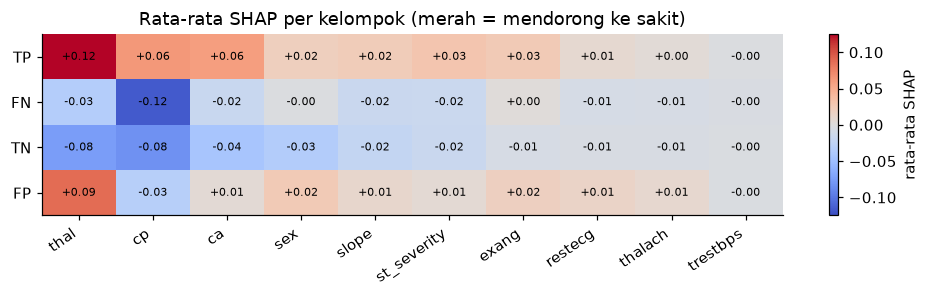

Korelasi profil SHAP FN dengan TP: -0.48 | dengan TN: +0.80


,age,sex,cp,thalach,exang,oldpeak,slope,ca,thal,n
TP,58.0,1.0,4.0,133.5,1.0,1.60,2.0,1.0,7.0,82
FN,57.0,1.0,3.0,158.0,0.0,0.20,1.0,0.0,3.0,29
TN,51.5,0.0,3.0,162.0,0.0,0.15,1.0,0.0,3.0,114
FP,57.0,1.0,4.0,147.0,0.0,0.60,2.0,0.0,7.0,17


In [28]:
grp = np.select([(info.y == 1) & (info.pred == 1), (info.y == 0) & (info.pred == 0), (info.y == 1) & (info.pred == 0)],
                ["TP", "TN", "FN"], "FP")
prof = S_grp.groupby(grp).mean().loc[["TP", "FN", "TN", "FP"], imp.index[:10]]

fig, ax = plt.subplots(figsize=(9, 2.8))
im = ax.imshow(prof.values, cmap="coolwarm", vmin=-np.abs(prof.values).max(), vmax=np.abs(prof.values).max(), aspect="auto")
ax.set_xticks(range(prof.shape[1]), prof.columns, rotation=35, ha="right"); ax.set_yticks(range(4), prof.index)
for i in range(prof.shape[0]):
    for j in range(prof.shape[1]):
        ax.text(j, i, f"{prof.values[i, j]:+.2f}", ha="center", va="center", fontsize=7.5)
plt.colorbar(im, ax=ax, label="rata-rata SHAP"); ax.set_title("Rata-rata SHAP per kelompok (merah = mendorong ke sakit)")
plt.tight_layout(); plt.show()

corr_tp = np.corrcoef(prof.loc["FN"], prof.loc["TP"])[0, 1]
corr_tn = np.corrcoef(prof.loc["FN"], prof.loc["TN"])[0, 1]
print(f"Korelasi profil SHAP FN dengan TP: {corr_tp:+.2f} | dengan TN: {corr_tn:+.2f}")

key = ["age", "sex", "cp", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
display(R.loc[info.index, key].groupby(grp).median().loc[["TP", "FN", "TN", "FP"]].assign(
    n=pd.Series(grp).value_counts()))

**Cara membaca:** ini temuan terpenting dari interpretasi. Profil SHAP pasien FN berkorelasi **+0,80 dengan TN** dan −0,48 dengan TP.
Nilai mentahnya juga sama: median FN untuk `cp` (3, non-angina), `thalach` (158), `exang` (0), `oldpeak` (0,2), `slope` (1), `ca` (0), dan `thal` (3, normal) **identik dengan pasien sehat**. Yang membedakan FN dari TN hanya usia (57 vs 51,5) dan jenis kelamin (laki-laki), dan itu tidak cukup.

Artinya, dilihat dari 13 fitur yang tersedia, pasien FN memang terlihat sehat. Mengikuti alur di soal:
- **Data**: bukan. Sebagian besar record FN utuh (tidak diimputasi, tidak outlier).
- **Model**: bukan penyebab utama. RF dan CNN sepakat di hampir semua FN, dan model lain kemungkinan juga akan kesulitan karena fiturnya memang tumpang-tindih.
- **Label / fitur**: paling mungkin. Target dataset ini adalah hasil binarisasi `num` 0–4 (0 = sehat, 1–4 = sakit). Pasien dengan penyakit ringan (`num` = 1) bisa saja belum menunjukkan tanda di tes olahraga maupun thallium. Sayangnya CSV kita hanya berisi target biner, jadi nilai `num` asli tidak bisa dicek. Kemungkinan kedua, ada informasi klinis penting (riwayat merokok, riwayat keluarga, dll.) yang tidak termasuk dalam 14 atribut ini.

FP adalah kebalikannya: median `cp` = 4 (asimtomatik), `slope` = 2, `thal` = 7, mirip pasien sakit, kecuali `ca` = 0.

**Implikasi untuk Erdi (imbalance):** class weighting/SMOTE menggeser keputusan agar lebih banyak pasien diprediksi sakit. Karena FN tumpang-tindih dengan TN di ruang fitur, kenaikan recall hampir pasti dibayar dengan turunnya specificity, pasien yang sehat yang profilnya serupa ikut tertarik. Kalau hasil D1 menunjukkan trade-off ini, analisis di sini menjelaskan penyebabnya.

## E6. Ringkasan temuan Instruksi 7

| # | Temuan | Bukti | Sumber masalah | Tindakan |
|---|---|---|---|---|
| 1 | Model terutama memakai `thal`, `cp`, `ca` (±60% importance); arah semua fitur sesuai EDA dan domain | C1, C2, C3 | — | tidak ada |
| 2 | `cp_1` (angina tipikal) mendorong kuat ke sehat, mengikuti data (31,6% sakit) yang kemungkinan dipengaruhi pola rujukan | C2, D1 | data (selection bias sampel) | dicatat sebagai limitasi generalisasi |
| 3 | `ca` dan `thal` adalah hasil pemeriksaan lanjutan; `ca` kemungkinan dari prosedur yang sama dengan penentuan label. Tanpa keduanya macro F1 −0,05 | E3, E2 | fitur (kemungkinan leakage kontekstual) | dipertahankan dan ditulis di limitasi dan batas penggunaan model |
| 4 | `ca_missing`, `thal_missing`, `restecg_1` masing-masing hanya 1 pasien dan tidak pernah bisa dipelajari; SHAP non-nolnya hanya artefak CNN | E1, E2 | fitur | tidak diubah (ablasi: Δ di bawah noise); rekomendasi dibuang di pipeline berikutnya |
| 5 | Imputasi modus mengisi "hasil tes normal" (`thal` = 3, `ca` = 0) pada pasien sakit dengan data kosong; jadi pendorong FN pasien 266 | E1, E4 | data (imputasi) | dicatat; hanya 2 pasien, tidak diubah |
| 6 | `hr_reserve` redundan dan memecah importance `thalach` | E2 | fitur | tidak diubah (ablasi: Δ di bawah noise) |
| 7 | 29 FN secara sistematis berprofil seperti pasien sehat; 13 pasien dengan `p_label` < 0,2 yang stabil di 3 repeat | E4, E5 | label (binarisasi `num`) atau fitur yang tidak tersedia | daftar diserahkan ke Anggota 3 sebagai bukti tambahan; **tidak** ada label yang diubah di sini |

**Koreksi data tambahan dari analisis ini: tidak ada.** Semua temuan di atas adalah keterbatasan yang perlu dijelaskan, bukan bukti kuat bahwa record tertentu salah. Mengubah label hanya karena model dan SHAP tidak setuju akan melanggar aturan soal, dan berisiko membuat model semakin yakin pada pola yang sudah ia punya.

# BAGIAN F | Bahan diskusi (Instruksi 9, bagian Miko)

**Apa yang diungkap SHAP/LIME tentang perilaku model?**
Model terutama mengandalkan hasil pemeriksaan jantung lanjutan (`thal`, `ca`) dan jenis nyeri dada (`cp`), dilengkapi tanda dari tes olahraga (`st_severity`/`slope`, `exang`) serta jenis kelamin.
Arah semua fitur konsisten dengan EDA #2 dan pengetahuan klinis, dan urutannya stabil antara KernelSHAP (ensemble) dan TreeSHAP (RF).
Perilaku yang tidak terduga hanya satu: angina tipikal (`cp_1`) dianggap tanda sehat. Ini bisa dijelaskan oleh komposisi data, bukan oleh kesalahan model.

**Apakah interpretasi menemukan masalah data tambahan?**
Ya. Ada tiga hal yang tidak terlihat dari metrik saja: (1) kemungkinan leakage kontekstual pada `ca`, sekaligus besarnya ketergantungan model pada fitur itu;
(2) imputasi modus yang mengisi "hasil normal" pada pasien sakit; (3) fitur langka yang secara struktural tidak bisa dipelajari.
Selain itu, interpretasi menjelaskan *mengapa* false negative banyak: pasien-pasien itu tidak bisa dibedakan dari pasien sehat dengan fitur yang tersedia.
Ini lebih mengarah ke keterbatasan label/fitur daripada ke model.

**Keterbatasan analisis interpretasi ini**
- KernelSHAP mengasumsikan fitur independen. Pada fitur yang berkorelasi (`thalach`–`hr_reserve`–`age`, `oldpeak`–`st_severity`–`slope`), pembagian kontribusi antar-kolom tidak unik, sehingga importance dibaca per kelompok informasi.
- Background hanya 10 centroid k-means (demi waktu komputasi), yang menimbulkan artefak SHAP = 0 pada sebagian pasien (C3). Background lebih besar akan lebih halus, tetapi beberapa kali lebih lambat.
- SHAP dihitung di ruang fitur hasil preprocessing (sudah log, clip, dan skala). Arahnya tetap benar karena transformasinya monoton, tetapi besar efek tidak bisa langsung diterjemahkan ke satuan klinis.
- Hanya repeat pertama CV (5 model) yang dijelaskan. Kesalahan yang sama terkonfirmasi pada rata-rata 3 repeat, tetapi nilai SHAP per pasien tetap bergantung pada satu pembagian fold.
- LIME memberi penjelasan yang berbeda karena definisinya berbeda, dan ambang aturannya ada di skala Min-Max.
- Uji ablasi bersifat diagnostik. Selisih untuk `hr_reserve` dan fitur langka di bawah noise antar-fold (std ±0,02–0,03), jadi tidak bisa disimpulkan bahwa membuangnya *meningkatkan* performa.
- Semua analisis di sini memakai baseline D0. Setelah dataset final (D2/D3) ditentukan, notebook harus dijalankan ulang dengan `FINAL` terisi.
  Kesimpulan besarnya diperkirakan tetap, tetapi angka dan daftar pasien bisa sedikit bergeser.

**Risiko keputusan cleaning yang perlu diingat tim**
Daftar 13 pasien "label?" sangat mungkin beririsan dengan daftar Cleanlab, karena keduanya memakai skor yang sama (probabilitas out-of-fold untuk label yang tercatat). Jadi irisan kedua daftar **bukan** dua bukti yang independen.

Pola FN yang mirip TN juga berarti bahwa mengoreksi label pasien-pasien ini justru menghapus kasus sulit yang paling perlu dipelajari model,
dan membuat skor CV tampak lebih bagus tanpa model benar-benar membaik.

## Reproduksi
1. Jalankan notebook Thufail lebih dulu (atau pastikan `./artifacts/split.json`, `cv_splits.json`, `oof_baseline.csv` sudah ada).
2. `pip install shap lime` (versi yang dipakai tercetak di sel A9).
3. `Run All`. Output tersimpan di `./artifacts/anggota4/`: `shap_oof.csv`, `oof_info.csv`, `salah_prediksi.csv`, `cv_ablation.csv`.
4. Setelah dataset final diputuskan: isi `FINAL` di sel A10, lalu `Run All` lagi. Test set tidak dipakai di notebook ini.